In [1]:
from pathlib import Path

import numpy as np
import lightning as L
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from minerva.data.data_modules.base import MinervaDataModule
from minerva.data.datasets.base import SimpleDataset
from minerva.models.nets.image.deeplabv3 import DeepLabV3, DeepLabV3RegressionHead
from minerva.transforms.transform import Repeat, CastTo, Unsqueeze, TransformPipeline

from utils.data import NumpyFolderReader

## Create the Data Module

In [2]:
root_data_dir = Path("../../../../data/processed/super_resolution/seismic_super_resolution/partition_method_random/")
seed = 42

In [3]:
###########################
# Train dataset
###########################
train_data_reader = NumpyFolderReader(
    root_data_dir / "train" / "data",
    sort_method=["text"]
)
train_label_reader = NumpyFolderReader(
    root_data_dir / "train" / "label",
    sort_method=["text"]
)
train_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)

train_label_transforms = TransformPipeline(
    [
        CastTo("float32"),
    ]
)

train_dataset = SimpleDataset(
    readers=[train_data_reader, train_label_reader],
    transforms=[train_data_transforms, train_label_transforms],
)

###########################
# Validation dataset
###########################
val_data_reader = NumpyFolderReader(
    root_data_dir / "val" / "data",
    sort_method=["text"],
)
val_label_reader = NumpyFolderReader(
    root_data_dir / "val" / "label",
    sort_method=["text"]
)
val_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)
val_label_transforms = TransformPipeline(
    [
        CastTo("float32"),
    ]
)

val_dataset = SimpleDataset(
    readers=[val_data_reader, val_label_reader],
    transforms=[val_data_transforms, val_label_transforms],
)

###########################
# Test dataset
###########################
test_data_reader = NumpyFolderReader(
    root_data_dir / "test" / "data",
    sort_method=["text"]
)
test_label_reader = NumpyFolderReader(
    root_data_dir / "test" / "label",
    sort_method=["text"]
)
test_data_transforms = TransformPipeline(
    [Unsqueeze(0), Repeat(axis=0, n_repetitions=3), CastTo("float32")]
)  # Transforms to first reader (data)
test_label_transforms = TransformPipeline([CastTo("float32")])

test_dataset = SimpleDataset(
    readers=[test_data_reader, test_label_reader],
    transforms=[test_data_transforms, test_label_transforms],
)

In [4]:
train_x, train_y = train_dataset[0]
print(f"Train sample shapes: {train_x.shape} (dtype: {train_x.dtype}), Label Shape: {train_y.shape} (dtype: {train_y.dtype})")

val_x, val_y = val_dataset[0]
print(f"Validation sample shapes: {val_x.shape} (dtype: {val_x.dtype}), Label Shape: {val_y.shape} (dtype: {val_y.dtype})")

test_x, test_y = test_dataset[0]
print(f"Test sample shapes: {test_x.shape} (dtype: {test_x.dtype}), Label Shape: {test_y.shape} (dtype: {test_y.dtype})")

Train sample shapes: (3, 128, 128) (dtype: float32), Label Shape: (256, 256) (dtype: float32)
Validation sample shapes: (3, 128, 128) (dtype: float32), Label Shape: (256, 256) (dtype: float32)
Test sample shapes: (3, 128, 128) (dtype: float32), Label Shape: (256, 256) (dtype: float32)


In [5]:
data_module = MinervaDataModule(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    batch_size=128,
    num_workers=4,
    drop_last=True,
    name="SeismicSuperResolution Dataset"
)

print(data_module)

          🆔 SeismicSuperResolution Dataset
└── Predict Split: test
📂 Datasets:
   ├── Train Dataset:
   │      ==================================================
   │                 📂 SimpleDataset Information            
   │      ==================================================
   │      📌 Dataset Type: SimpleDataset
   │         └── Reader 0: NumpyFolderReader at '../../../../data/processed/super_resolution/seismic_super_resolution/partition_method_random/train/data' (2240 files)
   │         │     └── Transform: TransformPipeline(transforms=[Unsqueeze(axis=0), Repeat(axis=0, n_repetitions=3), CastTo(dtype=float32)])
   │         └── Reader 1: NumpyFolderReader at '../../../../data/processed/super_resolution/seismic_super_resolution/partition_method_random/train/label' (2240 files)
   │         │     └── Transform: TransformPipeline(transforms=[CastTo(dtype=float32)])
   │         │
   │         └── Total Readers: 2
   │      ==================================================
   

### Plot a sample from the training set

In [6]:
def plot_data_label_slice(data, label, size=(12, 6), show=True):
    fig, axes = plt.subplots(1, 2, figsize=size)

    axes[0].imshow(data, cmap="gray")
    axes[0].set_title("Seismic Low Resolution Slice (input)")

    axes[1].imshow(label, cmap="gray", vmin=0, vmax=np.max(label))
    axes[1].set_title(f"Seismic High Resolution Slice (label)")
    # axes[1].colorbar = plt.colorbar(axes[1].images[0], ax=axes[1])

    plt.tight_layout()
    if show:
        plt.show()
    return fig

/tmp/ipykernel_116757/4006026116.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


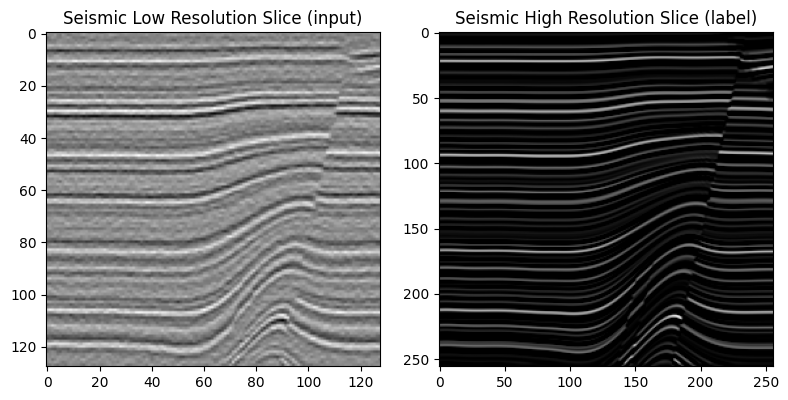

In [7]:
x, y = train_dataset[0]
fig = plot_data_label_slice(x[0,:,:], y, size=(8, 6), show=False)
fig.show()

## Model

In [8]:
def squeeze_channel_if_needed(x: torch.Tensor) -> torch.Tensor:
    if x.dim() == 3:
        x = x.unsqueeze(1)
    elif x.dim() == 4 and x.size(1) != 1:
        raise ValueError(f"Expected a single channel tensor, got shape {tuple(x.shape)}")
    return x


def normalize_pair_per_sample(
    pred: torch.Tensor,
    target: torch.Tensor,
    eps: float = 1e-6,
    return_params: bool = False,
) -> tuple[torch.Tensor, torch.Tensor] | tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    pred = squeeze_channel_if_needed(pred)
    target = squeeze_channel_if_needed(target)

    reduce_dims = (1, 2, 3)
    pair_max = torch.maximum(pred.amax(dim=reduce_dims, keepdim=True), target.amax(dim=reduce_dims, keepdim=True))
    pair_min = torch.minimum(pred.amin(dim=reduce_dims, keepdim=True), target.amin(dim=reduce_dims, keepdim=True))
    denom = torch.clamp(pair_max - pair_min, min=eps)

    pred_norm = (pred - pair_min) / denom
    target_norm = (target - pair_min) / denom

    if return_params:
        return pred_norm, target_norm, pair_min, pair_max
    return pred_norm, target_norm


def create_gaussian_window(window_size: int, channel: int, device: torch.device, dtype: torch.dtype) -> torch.Tensor:
    coords = torch.arange(window_size, device=device, dtype=dtype) - (window_size // 2)
    g = torch.exp(-(coords ** 2) / (2 * (1.5 ** 2)))
    g = g / g.sum()
    window_2d = torch.outer(g, g).unsqueeze(0).unsqueeze(0)
    return window_2d.expand(channel, 1, window_size, window_size).contiguous()


def ssim_score(
    x: torch.Tensor,
    y: torch.Tensor,
    window_size: int = 11,
    data_range: float = 1.0,
    eps: float = 1e-8,
    size_average: bool = True,
    full: bool = False,
) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
    x = squeeze_channel_if_needed(x)
    y = squeeze_channel_if_needed(y)

    _, channel, h, w = x.shape
    real_window_size = min(window_size, h, w)
    window = create_gaussian_window(real_window_size, channel, x.device, x.dtype)

    mu_x = F.conv2d(x, window, padding=0, groups=channel)
    mu_y = F.conv2d(y, window, padding=0, groups=channel)

    mu_x2 = mu_x.pow(2)
    mu_y2 = mu_y.pow(2)
    mu_xy = mu_x * mu_y

    sigma_x2 = F.conv2d(x * x, window, padding=0, groups=channel) - mu_x2
    sigma_y2 = F.conv2d(y * y, window, padding=0, groups=channel) - mu_y2
    sigma_xy = F.conv2d(x * y, window, padding=0, groups=channel) - mu_xy

    c1 = (0.01 * data_range) ** 2
    c2 = (0.03 * data_range) ** 2

    cs = (2 * sigma_xy + c2) / (sigma_x2 + sigma_y2 + c2 + eps)
    ssim_map = ((2 * mu_xy + c1) * (2 * sigma_xy + c2)) / ((mu_x2 + mu_y2 + c1) * (sigma_x2 + sigma_y2 + c2) + eps)

    if size_average:
        ssim_val = ssim_map.mean()
        cs_val = cs.mean()
    else:
        ssim_val = ssim_map.mean(dim=(1, 2, 3))
        cs_val = cs.mean(dim=(1, 2, 3))

    if full:
        return ssim_val, cs_val
    return ssim_val


def msssim_score(
    x: torch.Tensor,
    y: torch.Tensor,
    window_size: int = 11,
    data_range: float = 1.0,
    size_average: bool = True,
    normalize: bool = True,
) -> torch.Tensor:
    x = squeeze_channel_if_needed(x)
    y = squeeze_channel_if_needed(y)

    weights = torch.tensor([0.0448, 0.2856, 0.3001, 0.2363, 0.1333], device=x.device, dtype=x.dtype)
    mssim_vals = []
    mcs_vals = []

    for _ in range(len(weights)):
        sim, cs = ssim_score(
            x, y, window_size=window_size, data_range=data_range, size_average=size_average, full=True
        )
        mssim_vals.append(sim)
        mcs_vals.append(cs)

        x = F.avg_pool2d(x, kernel_size=2, stride=2)
        y = F.avg_pool2d(y, kernel_size=2, stride=2)

    mssim_vals = torch.stack(mssim_vals)
    mcs_vals = torch.stack(mcs_vals)

    if normalize:
        mssim_vals = (mssim_vals + 1) / 2
        mcs_vals = (mcs_vals + 1) / 2

    output = torch.prod((mcs_vals[:-1] ** weights[:-1]) * (mssim_vals[-1] ** weights[-1]))
    return output


class SRCombinedLoss(nn.Module):
    def __init__(self, msssim_weight: float = 0.6):
        super().__init__()
        self.msssim_weight = msssim_weight
        self.l1_weight = 1.0 - msssim_weight
        self.l1 = nn.L1Loss()

    def forward(self, input: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        pred_norm, target_norm = normalize_pair_per_sample(input, target)
        l1_term = self.l1(pred_norm, target_norm)
        msssim_term = 1.0 - msssim_score(pred_norm, target_norm, data_range=1.0)
        return self.l1_weight * l1_term + self.msssim_weight * msssim_term


model = DeepLabV3(
    num_classes=1,
    loss_fn=SRCombinedLoss(msssim_weight=0.6),
    pred_head=DeepLabV3RegressionHead(in_channels=2048, out_channels=1),
    loss_long=False,
    output_shape=(256, 256),
)

model

DeepLabV3(
  (backbone): DeepLabV3Backbone(
    (RN50model): ResNet(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu)

## Trainer

In [ ]:
accelerator = "gpu" if torch.cuda.is_available() else "cpu"

trainer = L.Trainer(
    max_epochs=100,
    logger=False,
    enable_checkpointing=False,
    accelerator=accelerator,
    devices=1,
    limit_train_batches=1.0,
    limit_val_batches=1.0,
    deterministic=True,
    log_every_n_steps=10,
    num_sanity_val_steps=0,
    precision="16-mixed"
)

trainer

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..


In [10]:
trainer.fit(model, data_module)

You are using a CUDA device ('NVIDIA RTX A6000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type                    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone │ DeepLabV3Backbone       │ 25.6 M │ train │     0 │
│ 1 │ fc       │ DeepLabV3RegressionHead │ 16.1 M │ train │     0 │
│ 2 │ loss_fn  │ SRCombinedLoss          │      0 │ train │     0 │
└───┴──────────┴─────────────────────────┴────────┴───────┴───────┘

Trainable params: 41.7 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 41.7 M                                                                                               
Total estimated model params size (MB): 166                                                                        
Modules in train mode: 187                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/core/module.py:522: You called 
`self.log('train_loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`

/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/core/module.py:522: You called 
`self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/home/vscode/.local/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Calculate metrics on the test set

In [11]:
def calc_psnr_like_reference(
    pred: torch.Tensor,
    target: torch.Tensor,
    scale: int = 2,
    data_range: float = 1.0,
    eps: float = 1e-10,
) -> torch.Tensor:
    # Matches the reference repository behavior: crop border before PSNR.
    diff = (pred - target) / data_range
    shave = scale + 6
    if diff.size(-2) <= 2 * shave or diff.size(-1) <= 2 * shave:
        valid = diff
    else:
        valid = diff[..., shave:-shave, shave:-shave]
    mse = valid.pow(2).mean()
    return -10.0 * torch.log10(torch.clamp(mse, min=eps))


device = model.device
model.eval()

test_inputs = []
test_targets = []
test_predictions = []

mse_values = []
mae_values = []
psnr_values = []
ssim_values = []

with torch.no_grad():
    for batch in data_module.test_dataloader():
        lr_batch, hr_batch = batch
        lr_batch = lr_batch.to(device)
        hr_batch = hr_batch.to(device)

        pred_batch = model(lr_batch)
        pred_batch = squeeze_channel_if_needed(pred_batch)
        hr_batch = squeeze_channel_if_needed(hr_batch)

        pred_norm, hr_norm = normalize_pair_per_sample(pred_batch, hr_batch)

        mse_values.append(F.mse_loss(pred_norm, hr_norm).item())
        mae_values.append(F.l1_loss(pred_norm, hr_norm).item())
        psnr_values.append(calc_psnr_like_reference(pred_norm, hr_norm, scale=2).item())
        ssim_values.append(ssim_score(pred_norm, hr_norm, data_range=1.0).item())

        test_inputs.append(lr_batch.detach().cpu())
        test_targets.append(hr_batch.detach().cpu())
        test_predictions.append(pred_batch.detach().cpu())

test_inputs = torch.cat(test_inputs, dim=0)
test_targets = torch.cat(test_targets, dim=0).squeeze(1)
test_predictions = torch.cat(test_predictions, dim=0).squeeze(1)

print(f"Test samples: {len(test_predictions)}")

Test samples: 640


In [12]:
print(f"Mean Squared Error (MSE): {np.mean(mse_values):.6f}")
print(f"Mean Absolute Error (MAE): {np.mean(mae_values):.6f}")
print(f"PSNR (reference-style, border cropped): {np.mean(psnr_values):.4f} dB")
print(f"SSIM: {np.mean(ssim_values):.6f}")

Mean Squared Error (MSE): 0.021070
Mean Absolute Error (MAE): 0.110993
PSNR (reference-style, border cropped): 16.7263 dB
SSIM: 0.135754


### Plot a prediction from the test set

In [13]:
def plot_data_label_prediction_slice(data, label, prediction, size=(24, 6), show=True):
    fig, axes = plt.subplots(1, 3, figsize=size)

    axes[0].imshow(data, cmap="gray")
    axes[0].set_title("Low-Resolution Seismic Slice (input)")

    axes[1].imshow(label, cmap="gray", vmin=0, vmax=np.max(label))
    axes[1].set_title("High-Resolution Seismic Slice (label)")

    axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=np.max(prediction))
    axes[2].set_title("Predicted Slice")

    plt.tight_layout()
    if show:
        plt.show()
    return fig

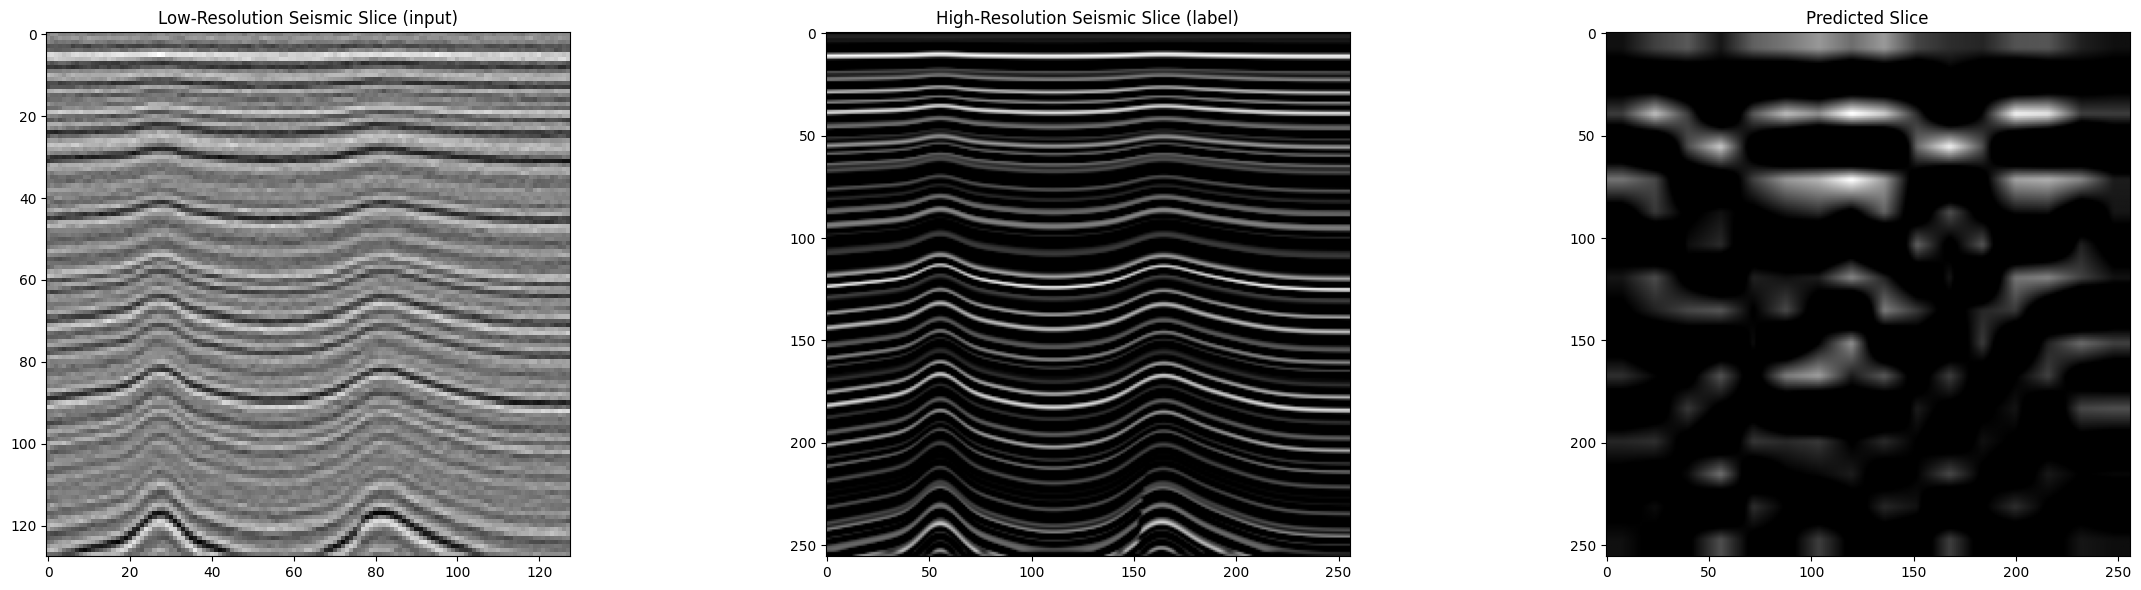

/tmp/ipykernel_116757/2664583711.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


In [14]:
index = 0
data = test_inputs[index][0, :, :].numpy()
label = test_targets[index].numpy()
prediction = test_predictions[index].numpy()

fig = plot_data_label_prediction_slice(
    data=data,
    label=label,
    prediction=prediction,
)
fig.show()